# Tópicos Avançados em Machine Learning
* Aluno: Brener Gomes dos Santos
* Data: 27/02/2026

In [93]:
import torch
from PIL import Image
from transformers import CLIPProcessor, CLIPModel, AutoProcessor, AutoModelForCausalLM

# Passo 1: Carrega e processa a imagem

In [94]:
image_path = "/content/dataset/39.jpg"

In [95]:
# image loading and preprocessing
def load_and_preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    inputs = processor(images=image, return_tensors="pt")
    return inputs, processor

# Passo 2: Extrai Embeddings da imagem com CLIP

In [96]:
# image understanding with CLIP
def generate_image_embeddings(inputs):
    model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
    with torch.no_grad():
        image_features = model.get_image_features(**inputs)

    return image_features, model

In [97]:
candidate_captions = [
  "a mouse",
  "a black mouse",
  "a wireless mouse",
  "a computer mouse",
  "other object",
  "a video game controller",
  "a red controller",
  "a camouflage controller",
  "a wireless controller",
  "other object",
  "a mug",
  "a blue mug",
  "a coffee mug",
  "a ceramic mug",
  "a calculator",
  "a black calculator",
  "a scientific calculator",
  "a math calculator",
  "a video game controller",
  "a black controller",
  "a wired controller",
  "a usb controller",
  "a bottle",
  "a pink bottle",
  "a thermos bottle",
  "a coffee bottle",
    "Mouse óptico preto com design minimalista.",
  "Mouse sem fio de superfície brilhante sobre fundo branco.",
  "Periférico de computador preto para navegação.",
  "Mouse moderno e ergonômico com scroll central.",
  "Dispositivo apontador wireless de cor preta.",
  "Vista superior de um mouse preto sem fio.",
  "Close-up do botão de rolagem de um mouse preto.",
  "Mouse preto refletindo a luz em ambiente claro.",
  "Versão espelhada de um mouse óptico preto.",
  "Mouse preto em perspectiva diagonal sobre mesa branca.",
  "Detalhe da textura lisa de um mouse wireless.",
  "Mouse preto com baixo contraste para simulação de sombra.",
  "Enquadramento aproximado de um mouse de computador.",
  "Mouse preto posicionado verticalmente no centro.",
  "Acessório de informática preto com acabamento em black piano.",
  "Controle Camuflado.",
  "Controle de videogame com estampa camuflada vermelha e preta.",
  "Gamepad wireless dualshock para consoles de jogos.",
  "Joystick de alta performance com acabamento personalizado.",
  "Controle sem fio para jogos com botões direcionais e analógicos.",
  "Acessório de gaming vermelho com padrão militar.",
  "Controle de jogos vermelho camuflado em fundo branco.",
  "Vista frontal de um gamepad personalizado vermelho.",
  "Detalhe dos analógicos de um controle de videogame.",
  "Controle gamer com estampa rubra e manchas pretas.",
  "Joystick moderno com design de camuflagem urbana vermelha.",
  "Controle de console em ângulo inclinado.",
  "Imagem com ruído de um controle de jogos camuflado.",
  "Foco nos botões de ação de um controle vermelho.",
  "Controle sem fio com luz de status visível.",
  "Gamepad com textura fosca e cores vibrantes.",
  "Caneca de cerâmica azul escura para bebidas quentes.",
  "Xícara de café azul marinho com alça lateral.",
  "Utensílio de cozinha azul para tomar chá ou café.",
  "Caneca clássica de cor sólida em ambiente iluminado.",
  "Recipiente de porcelana azul para líquidos.",
  "Caneca azul em close-up mostrando o interior escuro.",
  "Vista lateral de uma xícara azul profunda.",
  "Caneca de café sobre superfície branca com sombra suave.",
  "Recorte da alça de uma caneca azul marinho.",
  "Caneca azul com brilho ajustado para tons mais claros.",
  "Objeto cilíndrico azul para uso doméstico.",
  "Caneca de chá azul posicionada à direita do quadro.",
  "Variação de cor de uma caneca azul em luz artificial.",
  "Caneca de cerâmica robusta de cor escura.",
  "Xícara azul minimalista para escritório.",
  "Calculadora científica preta da marca Idea.",
  "Dispositivo eletrônico para cálculos matemáticos complexos.",
  "Calculadora escolar com visor digital e diversas funções.",
  "Ferramenta de cálculo para engenharia e computação.",
  "Calculadora de bolso preta sobre mesa branca.",
  "Vista de cima de uma calculadora científica invertida.",
  "Teclado numérico de uma calculadora científica em detalhe.",
  "Calculadora preta com botões cinzas e laranjas.",
  "Dispositivo de cálculo com logomarca visível.",
  "Calculadora científica em ângulo reto sobre fundo claro.",
  "Imagem aproximada do visor de uma calculadora Idea.",
  "Calculadora com alto contraste realçando os números.",
  "Equipamento de matemática para estudantes e profissionais.",
  "Calculadora científica preta em perspectiva horizontal.",
  "Ferramenta de produtividade com múltiplas teclas de função.",
  "Controle de videogame preto com cabo USB enrolado.",
  "Gamepad clássico com conexão via fio para PC ou console.",
  "Joystick preto de plástico com botões de ação e gatilhos.",
  "Controle gamer com fio e conectores padrão.",
  "Periférico de jogos analógico com cabo de conexão.",
  "Controle com fio preto emaranhado sobre a mesa.",
  "Detalhe do conector USB de um controle de jogo.",
  "Vista superior de um gamepad preto com fio central.",
  "Joystick clássico com botões direcionais visíveis.",
  "Controle com cabo em perspectiva desordenada.",
  'Gamepad preto com brilho reduzido e sombras marcadas.',
  "Acessório de jogos retro com conexão por fio.",
  "Close-up dos botões frontais de um controle com cabo.",
  "Controle de plástico preto com cabo USB estendido.",
  "Periférico de jogo com layout tradicional e fio.",
  "Garrafa térmica de cor rosa para conservar temperatura.",
  "Recipiente térmico com alça para servir café ou chá.",
  "Garrafa plástica rosa com design texturizado.",
  "Garrafa de armazenamento de líquidos quentes ou frios.",
  "Utensílio doméstico rosa para transporte de bebidas.",
  "Vista aérea de uma garrafa térmica rosa.",
  "Garrafa térmica com detalhe trançado na parte superior.",
  "Recipiente rosa com tampa arredondada e alça lateral.",
  "Garrafa térmica rosa em fundo branco com sombra longa.",
  "Imagem aproximada da textura de uma garrafa rosa.",
  "Garrafa de café rosa com brilho suave.",
  "Variação de saturação de uma garrafa térmica rosa.",
  "Garrafa para líquidos com isolamento térmico na cor rosa.",
  "Utensílio de cozinha rosa em perspectiva vertical.",
  "Garrafa térmica clássica com alça ergonômica rosa."
]

# Passo 3: Associa à imagem a legenda

In [98]:
# caption matching (using CLIP text embeddings)
def match_captions(image_features, captions, clip_model, processor):
    # 1. get text embeddings for the captions:
    text_inputs = processor(text=captions, return_tensors="pt", padding=True)
    with torch.no_grad():
        text_features = clip_model.get_text_features(**text_inputs)

    # 2. calculate cosine similarity between image and text features:
    # Convert PyTorch tensors to NumPy arrays for scikit-learn's cosine_similarity
    image_features = image_features.pooler_output.detach().cpu().numpy()
    text_features = text_features.pooler_output.detach().cpu().numpy()

    similarities = cosine_similarity(image_features, text_features)

    # 3. find the best matching captions:
    best_indices = similarities.argsort(axis=1)[0][::-1]
    best_captions = [captions[i] for i in best_indices]

    return best_captions, similarities[0][best_indices].tolist()

# Passo 4: Embrulha tudo junto

In [99]:
from sklearn.metrics.pairwise import cosine_similarity

In [100]:
# main function
def image_captioning(image_path, candidate_captions):
    inputs, processor = load_and_preprocess_image(image_path)
    image_features, clip_model = generate_image_embeddings(inputs)

    best_captions, similarities = match_captions(image_features, candidate_captions, clip_model, processor)
    return best_captions, similarities


best_captions, similarities = image_captioning(image_path, candidate_captions)

top_n = min(5, len(best_captions))
top_best_captions = best_captions[:top_n]
top_similarities = similarities[:top_n]

print("Top 5 Best Captions:")
for i, (caption, similarity) in enumerate(zip(top_best_captions, top_similarities)):
    print(f"{i+1}. {caption} (Similarity: {similarity:.4f})")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Top 5 Best Captions:
1. a black calculator (Similarity: 0.3074)
2. a scientific calculator (Similarity: 0.3013)
3. a calculator (Similarity: 0.3003)
4. a math calculator (Similarity: 0.2991)
5. Equipamento de matemática para estudantes e profissionais. (Similarity: 0.2902)


## Observações:
As legendas são claramente relacionadas a calculadoras. As pontuações de similaridade, embora não sejam muito altas, indicam uma consistência temática do modelo em identificar o objeto principal da imagem como uma calculadora.

# Property Listing Description Generator

In [101]:
import torch
from PIL import Image
from transformers import CLIPProcessor, CLIPModel
from sklearn.metrics.pairwise import cosine_similarity

In [102]:
# image path from private kaggle dataset

image_path = "/content/dataset/5.jpg"

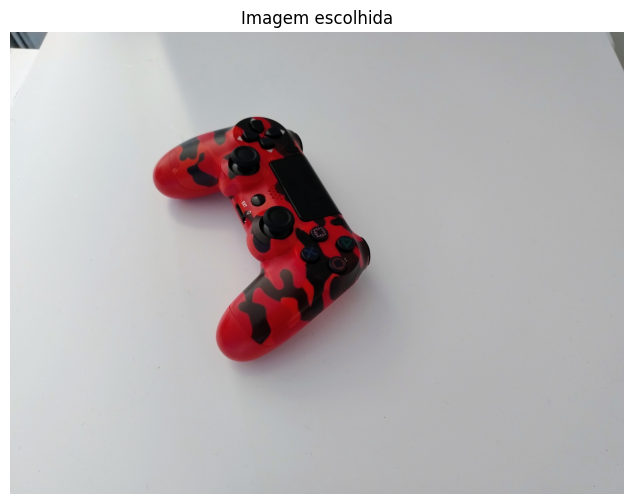

In [103]:
import matplotlib.pyplot as plt

# Display image in Kaggle
image = Image.open(image_path)
plt.figure(figsize=(10, 6))
plt.imshow(image)
plt.axis('off')
plt.title('Imagem escolhida')
plt.show()

In [104]:
property_descriptions = [
  "Mouse óptico preto com design minimalista.",
  "Mouse sem fio de superfície brilhante sobre fundo branco.",
  "Periférico de computador preto para navegação.",
  "Mouse moderno e ergonômico com scroll central.",
  "Dispositivo apontador wireless de cor preta.",
  "Vista superior de um mouse preto sem fio.",
  "Close-up do botão de rolagem de um mouse preto.",
  "Mouse preto refletindo a luz em ambiente claro.",
  "Versão espelhada de um mouse óptico preto.",
  "Mouse preto em perspectiva diagonal sobre mesa branca.",
  "Detalhe da textura lisa de um mouse wireless.",
  "Mouse preto com baixo contraste para simulação de sombra.",
  "Enquadramento aproximado de um mouse de computador.",
  "Mouse preto posicionado verticalmente no centro.",
  "Acessório de informática preto com acabamento em black piano.",
  "Controle Camuflado.",
  "Controle de videogame com estampa camuflada vermelha e preta.",
  "Gamepad wireless dualshock para consoles de jogos.",
  "Joystick de alta performance com acabamento personalizado.",
  "Controle sem fio para jogos com botões direcionais e analógicos.",
  "Acessório de gaming vermelho com padrão militar.",
  "Controle de jogos vermelho camuflado em fundo branco.",
  "Vista frontal de um gamepad personalizado vermelho.",
  "Detalhe dos analógicos de um controle de videogame.",
  "Controle gamer com estampa rubra e manchas pretas.",
  "Joystick moderno com design de camuflagem urbana vermelha.",
  "Controle de console em ângulo inclinado.",
  "Imagem com ruído de um controle de jogos camuflado.",
  "Foco nos botões de ação de um controle vermelho.",
  "Controle sem fio com luz de status visível.",
  "Gamepad com textura fosca e cores vibrantes.",
  "Caneca de cerâmica azul escura para bebidas quentes.",
  "Xícara de café azul marinho com alça lateral.",
  "Utensílio de cozinha azul para tomar chá ou café.",
  "Caneca clássica de cor sólida em ambiente iluminado.",
  "Recipiente de porcelana azul para líquidos.",
  "Caneca azul em close-up mostrando o interior escuro.",
  "Vista lateral de uma xícara azul profunda.",
  "Caneca de café sobre superfície branca com sombra suave.",
  "Recorte da alça de uma caneca azul marinho.",
  "Caneca azul com brilho ajustado para tons mais claros.",
  "Objeto cilíndrico azul para uso doméstico.",
  "Caneca de chá azul posicionada à direita do quadro.",
  "Variação de cor de uma caneca azul em luz artificial.",
  "Caneca de cerâmica robusta de cor escura.",
  "Xícara azul minimalista para escritório.",
  "Calculadora científica preta da marca Idea.",
  "Dispositivo eletrônico para cálculos matemáticos complexos.",
  "Calculadora escolar com visor digital e diversas funções.",
  "Ferramenta de cálculo para engenharia e computação.",
  "Calculadora de bolso preta sobre mesa branca.",
  "Vista de cima de uma calculadora científica invertida.",
  "Teclado numérico de uma calculadora científica em detalhe.",
  "Calculadora preta com botões cinzas e laranjas.",
  "Dispositivo de cálculo com logomarca visível.",
  "Calculadora científica em ângulo reto sobre fundo claro.",
  "Imagem aproximada do visor de uma calculadora Idea.",
  "Calculadora com alto contraste realçando os números.",
  "Equipamento de matemática para estudantes e profissionais.",
  "Calculadora científica preta em perspectiva horizontal.",
  "Ferramenta de produtividade com múltiplas teclas de função.",
  "Controle de videogame preto com cabo USB enrolado.",
  "Gamepad clássico com conexão via fio para PC ou console.",
  "Joystick preto de plástico com botões de ação e gatilhos.",
  "Controle gamer com fio e conectores padrão.",
  "Periférico de jogos analógico com cabo de conexão.",
  "Controle com fio preto emaranhado sobre a mesa.",
  "Detalhe do conector USB de um controle de jogo.",
  "Vista superior de um gamepad preto com fio central.",
  "Joystick clássico com botões direcionais visíveis.",
  "Controle com cabo em perspectiva desordenada.",
  'Gamepad preto com brilho reduzido e sombras marcadas.',
  "Acessório de jogos retro com conexão por fio.",
  "Close-up dos botões frontais de um controle com cabo.",
  "Controle de plástico preto com cabo USB estendido.",
  "Periférico de jogo com layout tradicional e fio.",
  "Garrafa térmica de cor rosa para conservar temperatura.",
  "Recipiente térmico com alça para servir café ou chá.",
  "Garrafa plástica rosa com design texturizado.",
  "Garrafa de armazenamento de líquidos quentes ou frios.",
  "Utensílio doméstico rosa para transporte de bebidas.",
  "Vista aérea de uma garrafa térmica rosa.",
  "Garrafa térmica com detalhe trançado na parte superior.",
  "Recipiente rosa com tampa arredondada e alça lateral.",
  "Garrafa térmica rosa em fundo branco com sombra longa.",
  "Imagem aproximada da textura de uma garrafa rosa.",
  "Garrafa de café rosa com brilho suave.",
  "Variação de saturação de uma garrafa térmica rosa.",
  "Garrafa para líquidos com isolamento térmico na cor rosa.",
  "Utensílio de cozinha rosa em perspectiva vertical.",
  "Garrafa térmica clássica com alça ergonômica rosa."
]

In [105]:
def load_and_preprocess_image(image_path):
    """Load and preprocess property image"""
    image = Image.open(image_path).convert("RGB")
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    inputs = processor(images=image, return_tensors="pt")
    return inputs, processor

In [106]:
def generate_image_embeddings(inputs):
    """Generate image embeddings using CLIP"""
    model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
    with torch.no_grad():
        image_features = model.get_image_features(**inputs)
    return image_features, model

In [107]:
def match_descriptions(image_features, descriptions, clip_model, processor):
    """Match image to property descriptions"""
    # Get text embeddings for descriptions
    text_inputs = processor(text=descriptions, return_tensors="pt", padding=True)
    with torch.no_grad():
        text_features = clip_model.get_text_features(**text_inputs)

    # Calculate cosine similarity
    image_features = image_features.pooler_output.detach().cpu().numpy()
    text_features = text_features.pooler_output.detach().cpu().numpy()
    similarities = cosine_similarity(image_features, text_features)

    # Find best matching descriptions
    best_indices = similarities.argsort(axis=1)[0][::-1]
    best_descriptions = [descriptions[i] for i in best_indices]

    return best_descriptions, similarities[0][best_indices].tolist()

In [108]:
def generate_property_listing(image_path, descriptions=property_descriptions, top_n=5):
    """Main function to generate property listing descriptions"""
    inputs, processor = load_and_preprocess_image(image_path)
    image_features, clip_model = generate_image_embeddings(inputs)

    best_descriptions, similarities = match_descriptions(
        image_features, descriptions, clip_model, processor
    )

    # Return top N descriptions
    top_descriptions = best_descriptions[:top_n]
    top_similarities = similarities[:top_n]

    return top_descriptions, top_similarities

In [109]:
def debug_property_listing(image_path):
    descriptions, scores = generate_property_listing(image_path)

    print(f"Max similarity score: {max(scores):.3f}")
    print(f"Min similarity score: {min(scores):.3f}")
    print(f"Average score: {sum(scores)/len(scores):.3f}")
    print("\nProperty Description Suggestions:")
    for i, (desc, score) in enumerate(zip(descriptions, scores)):
        print(f"{i+1}. {desc} (Confidence: {score:.3f})")

    return descriptions, scores

In [110]:
 #  Test with simple words
words = ["Gamepad", "Mouse", "Garrafa", "Caneca", "Calculadora"]

# Run this instead:
debug_property_listing(image_path)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIPModel LOAD REPORT from: openai/clip-vit-base-patch32
Key                                  | Status     |  | 
-------------------------------------+------------+--+-
text_model.embeddings.position_ids   | UNEXPECTED |  | 
vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Max similarity score: 0.320
Min similarity score: 0.306
Average score: 0.312

Property Description Suggestions:
1. Controle gamer com estampa rubra e manchas pretas. (Confidence: 0.320)
2. Controle de jogos vermelho camuflado em fundo branco. (Confidence: 0.315)
3. Controle gamer com fio e conectores padrão. (Confidence: 0.313)
4. Joystick moderno com design de camuflagem urbana vermelha. (Confidence: 0.308)
5. Gamepad com textura fosca e cores vibrantes. (Confidence: 0.306)


(['Controle gamer com estampa rubra e manchas pretas.',
  'Controle de jogos vermelho camuflado em fundo branco.',
  'Controle gamer com fio e conectores padrão.',
  'Joystick moderno com design de camuflagem urbana vermelha.',
  'Gamepad com textura fosca e cores vibrantes.'],
 [0.319776713848114,
  0.31514906883239746,
  0.3127327561378479,
  0.30779528617858887,
  0.30637502670288086])

## Observações:
As descrições sugeridas são todas sobre controles de videogame, especificamente modelos camuflados vermelhos, só peca ao afirmar que é um controle com fio. As pontuações de confiança são um pouco mais altas do que no primeiro caso, mas ainda indicam que a correspondência não é perfeita, embora as descrições sejam semanticamente muito relevantes para o que a imagem provavelmente representa.